# Actividad 1 — Mejora adaptada a cada imagen

Cuatro fotografías en `archive/image/`, todas oscuras pero con problemas distintos. Seguimos la **misma metodología del laboratorio**: trabajar **siempre en RGB** (`img_rgb`) y aplicar transformaciones de intensidad (gamma, lineal, a trozos, ecualización, CLAHE) directamente sobre los tres canales. No se convierte a escala de grises ni a LAB/HSV.

| Imagen | Observación | Pipeline | Método principal |
|---|---|---|---|
| `81.png` | media 13.7, mucha estructura | Lineal + CLAHE | corrección lineal + contraste local |
| `87.png` | media 8.5, ruido rojo en sombras, carteles luminosos | Limpieza de croma + balance suave + gamma | gamma (protege luces y saturación) |
| `156.png` | media 16.2, escaparate muy brillante (p99=195) | Lineal en sombras (3.1) | corrección lineal + máscara de sombras |
| `521.png` | media 5.3, casi negra, con ruido | Ecualización global limitada + mezcla | ecualización con recorte de histograma |

> Ejecutar desde la carpeta `VA/` (rutas relativas a `archive/image/`).


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_DIR = "archive/image/"

In [2]:
# Funciones auxiliares (adaptadas a RGB)

def plot_img_and_hist(image, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(image)  # imagen RGB
    axes[0].set_title(title)
    axes[0].axis('off')

    axes[1].hist(image.reshape(-1, 3), bins=256, range=[0, 256],
                 color=['#d62728', '#2ca02c', '#1f77b4'], histtype='step')
    axes[1].set_title("Histograma (R, G, B)")
    axes[1].set_xlim([0, 256])
    plt.tight_layout()
    plt.show()

def plot_hist_rgb(image, title="Histograma por canal"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    colors = ("red", "green", "blue")
    for ax, color, name in zip(axes, colors, "RGB"):
        ax.hist(image[..., "RGB".index(name)].ravel(), bins=256, range=(0,256), color=color, alpha=0.7)
        ax.set_title(f"Canal {name}")
        ax.set_xlim(0,255)
        ax.set_xlabel("Intensidad")
        ax.set_ylabel("Píxeles")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def adjust_gamma(image, gamma=1.0):
    # Gamma canal a canal (para las curvas de punto).
    img_norm = image.astype(np.float32) / 255.0
    return (np.power(img_norm, gamma) * 255).astype(np.uint8)


def gamma_luminance_rgb(image, gamma=1.0):
    # Gamma sobre el brillo (max canal) escalando R,G,B en la misma
    # proporcion: aclara sombras y comprime luces sin desaturar el color.
    img = image.astype(np.float32)
    bright = img.max(axis=2, keepdims=True)
    bright2 = np.power(bright / 255.0, gamma) * 255.0
    scale = bright2 / np.maximum(bright, 1e-6)
    return np.clip(img * scale, 0, 255).astype(np.uint8)


def clean_shadow_chroma(image, amount=1.0, threshold=70):
    # Lleva las sombras hacia su luminancia para quitar dominantes y ruido
    # de color. Los pixeles con brillo >= threshold no se tocan.
    img = image.astype(np.float32)
    bright = img.max(axis=2, keepdims=True)
    weight = np.clip(1.0 - bright / threshold, 0.0, 1.0)
    lum = 0.299 * img[..., 0:1] + 0.587 * img[..., 1:2] + 0.114 * img[..., 2:3]
    return img + amount * weight * (lum - img)


def white_balance_gray_world(image, strength=1.0):
    # Iguala las medias de R, G y B, pero normaliza la ganancia maxima a 1:
    # solo atenua canales dominantes, nunca amplifica, para no recortar luces.
    img = image.astype(np.float32)
    means = img.reshape(-1, 3).mean(axis=0)
    gain = (means.mean() / means) ** strength
    gain /= gain.max()
    return np.clip(img * gain, 0, 255)


def denoise_dark(image, ksize=5, threshold=35):
    # Mediana solo en sombras profundas: quita ruido del cielo/sombras
    # sin tocar los carteles ni los bordes de las luces fuertes.
    img = image.astype(np.float32)
    bright = img.max(axis=2, keepdims=True)
    weight = np.clip(1.0 - bright / threshold, 0.0, 1.0)
    den = cv2.medianBlur(np.clip(image, 0, 255).astype(np.uint8), ksize).astype(np.float32)
    return img * (1.0 - weight) + den * weight


def clahe_rgb(image, clip=2.0, tile=(8, 8)):
    # CLAHE de OpenCV es monobanda: se aplica a cada canal y se vuelve a unir.
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile)
    return np.stack([clahe.apply(image[..., c]) for c in range(3)], axis=-1)


def equalize_rgb(image, blend=1.0):
    # Ecualizacion por canal y mezcla opcional con el original.
    eq = np.stack([cv2.equalizeHist(image[..., c]) for c in range(3)], axis=-1)
    if blend < 1.0:
        return cv2.addWeighted(image, 1.0 - blend, eq, blend, 0)
    return eq

def linear_rgb(image, alpha=1.0, beta=0):
    # Transformacion lineal del laboratorio: g = alpha * f + beta.
    return np.clip(image.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)


def shadow_mask(image, threshold=80):
    # 1 en sombra profunda, 0 cuando el brillo llega al umbral.
    bright = image.astype(np.float32).max(axis=2, keepdims=True)
    return np.clip(1.0 - bright / threshold, 0.0, 1.0)


def masked_merge(original, enhanced, mask):
    # Aplica el metodo solo donde la mascara vale 1 (sombras).
    return np.clip(original.astype(np.float32) * (1.0 - mask) +
                   enhanced.astype(np.float32) * mask, 0, 255).astype(np.uint8)


def linear_shadow_rgb(image, alpha=(2.9, 3.4, 3.4), beta=0, mask=None, threshold=80):
    # Correccion lineal solo en sombras: sube contraste sin levantar el negro
    # (beta=0) y sin recortar el escaparate ni la ropa blanca. El alfa de R
    # es algo menor porque las sombras ya vienen con dominante roja.
    if mask is None:
        mask = shadow_mask(image, threshold)
    return masked_merge(image, linear_rgb(image, alpha, beta), mask)


In [3]:
def load_rgb(name):
    bgr = cv2.imread(IMG_DIR + name)
    if bgr is None:
        raise FileNotFoundError(IMG_DIR + name)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

for name in ["81.png", "87.png", "156.png", "521.png"]:
    img = load_rgb(name)
    rgb_mean = img.reshape(-1, 3).mean(axis=0).round(1)
    print(f"{name:8s} media={img.mean():5.1f} std={img.std():5.1f} p50={np.median(img):5.1f} "
          f"p1={np.percentile(img,1):5.1f} p99={np.percentile(img,99):5.1f} min={img.min()} max={img.max()} "
          f"R/G/B={rgb_mean}")


81.png   media= 13.7 std= 28.2 p50=  4.0 p1=  0.0 p99=150.0 min=0 max=255 R/G/B=[14.1 11.8 15.1]
87.png   media=  8.5 std= 24.8 p50=  3.0 p1=  0.0 p99=164.0 min=0 max=255 R/G/B=[11.2  6.8  7.4]
156.png  media= 16.2 std= 34.2 p50=  4.0 p1=  0.0 p99=195.0 min=0 max=255 R/G/B=[18.9 15.4 14.2]
521.png  media=  5.3 std= 19.1 p50=  2.0 p1=  0.0 p99=105.0 min=0 max=255 R/G/B=[5.3 4.9 5.8]


## Análisis de las imágenes (RGB)

| Imagen | media | p50 | p1 | p99 | min | max |
|---|---|---|---|---|---|---|
| `81.png` | 13.7 | 4 | 0 | 150 | 0 | 255 |
| `87.png` | 8.5 | 3 | 0 | 164 | 0 | 255 |
| `156.png` | 16.2 | 4 | 0 | 195 | 0 | 255 |
| `521.png` | 5.3 | 2 | 0 | 105 | 0 | 255 |

Observaciones clave (calculadas sobre los valores RGB):

- Todas tienen `p50` muy bajo: son imágenes **subexpuestas** (la mayoría de píxeles son casi negros).
- Todas tienen `min=0` y `max=255`, por eso **el estiramiento min-max no sirve**: estirar [0,255] a [0,255] es la identidad (ya lo vimos en el laboratorio). Hay que usar curvas no lineales o ecualización.
- `81` conserva mucha estructura en zonas oscuras → conviene **contraste local**.
- `87` tiene carteles muy luminosos y **ruido rojo en las sombras**. Una lineal amplifica el rojo y recorta las luces; la gamma por canal desatura los carteles. Conviene **limpiar el croma de las sombras + balance suave + gamma sobre el brillo**.
- `156` es la única con una zona realmente brillante (p99=195) → hay que **tratarla distinto** de las sombras.
- `521` es la más oscura y ruidosa (con un pico enorme en 0) → **ecualización global con recorte de histograma**, para repartir la poca señal sin amplificar el ruido del cielo.

Todos los métodos se aplican sobre los tres canales (por igual, por canal, o escalando el brillo según el caso), sin pasar por grises ni HSV, para conservar el color de la escena.


## Pipeline 1 — `81.png`: corrección lineal + CLAHE (RGB)

**Naturaleza (RGB):** media 13.7, mediana 4, `p99 = 150`. Muy oscura pero con detalle repartido por toda la escena: conviene subir brillo/contraste global y después realzar el detalle local.

**Método (lo que hace el código):**
1. **Corrección lineal** `g = α·f + β` con `α = 2.0`, `β = 2` (`linear_rgb`): sube contraste (α) y brillo (β) de forma **punto a punto**, sin tocar los bordes.
2. **CLAHE** sobre cada canal R, G y B (`clahe_rgb`, `clip = 2.0`, `tile = (8, 8)`): añade contraste **local**; el `clipLimit` bajo evita amplificar demasiado el ruido.
3. **Mezcla** al 10 % con la original (`cv2.addWeighted`): suaviza el recorte de luces y conserva la estructura.

**Resultado:** media 13.7 → 35.7, mediana 4 → 16, `p99` 150 → 244 y solo ~0.06 % de píxeles recortados a 255.

**Por qué no gamma:** amplificaba el ruido de las sombras y difuminaba las luces. **Por qué no min-max:** los valores ya ocupan 0–255, así que no cambiaría nada.


Antes:  media=13.7 p50=4.0
Despues: media=35.7 p50=16.0


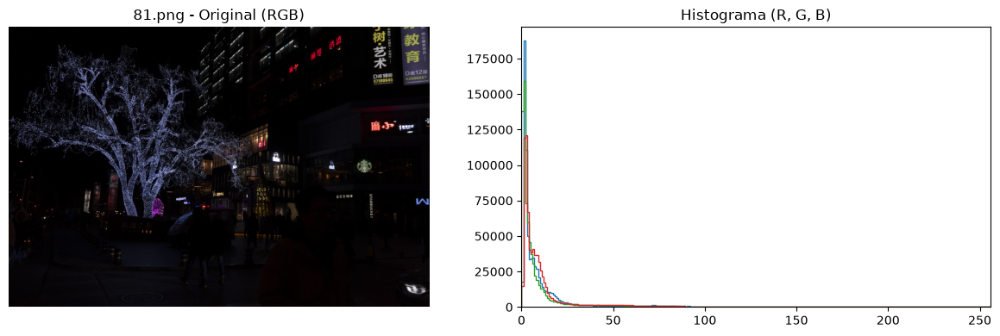

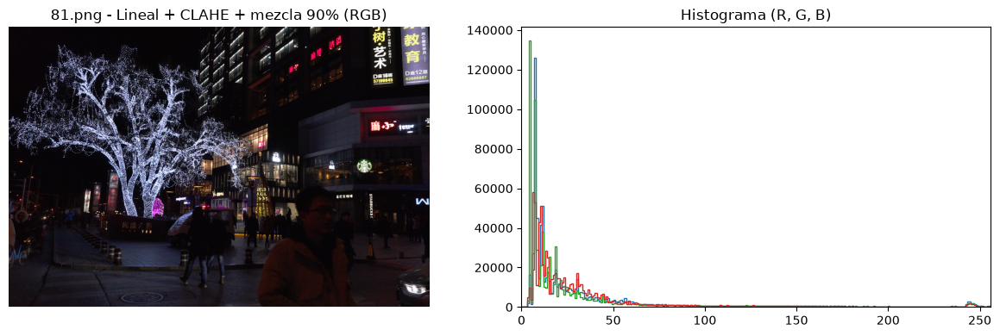

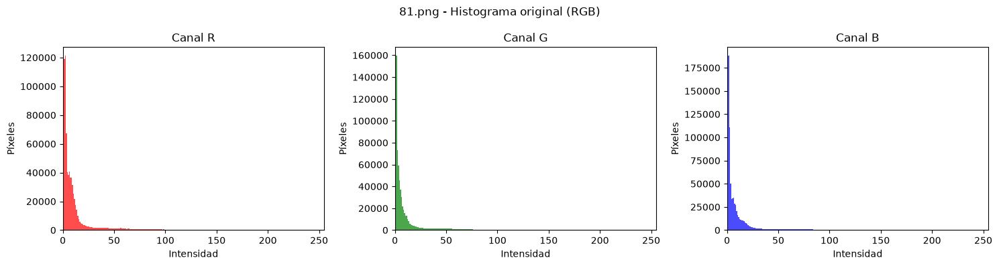

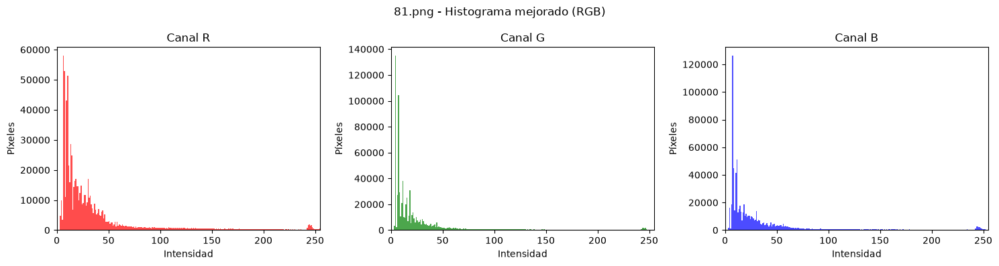

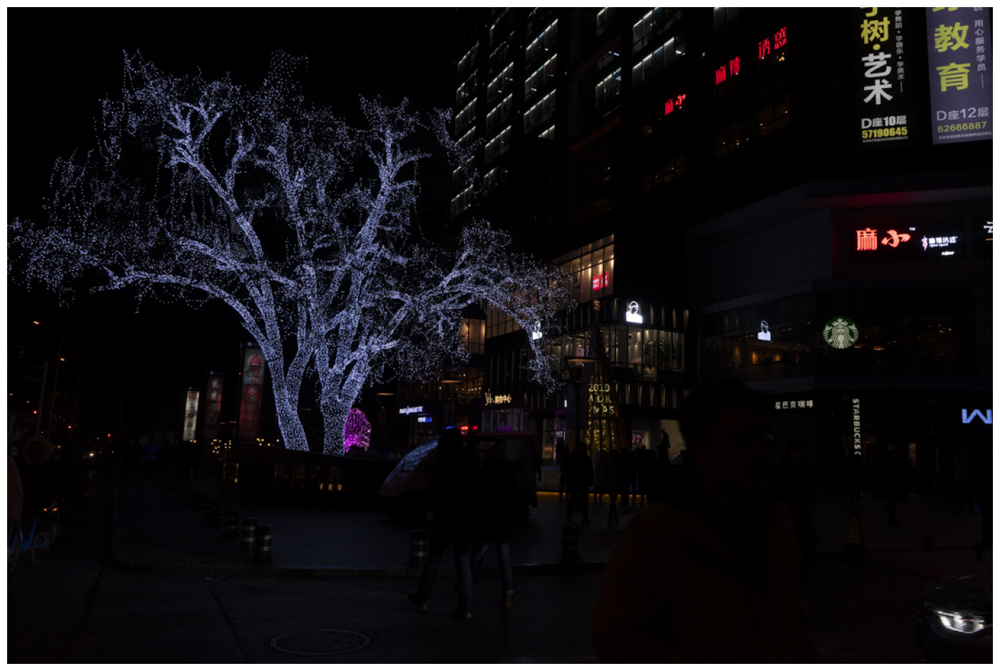

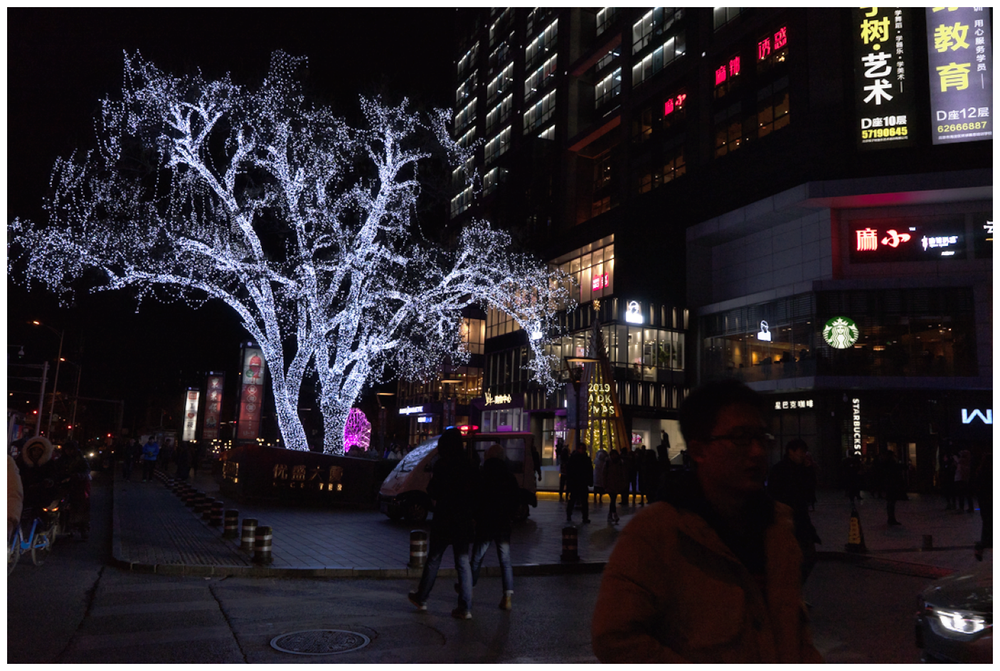

In [4]:
img_rgb = load_rgb("81.png")
print("Antes:  media=%.1f p50=%.1f" % (img_rgb.mean(), np.median(img_rgb)))

img_lin = linear_rgb(img_rgb, alpha=2.0, beta=2)
img_clahe = clahe_rgb(img_lin, clip=2.0, tile=(8, 8))
result_81 = cv2.addWeighted(img_rgb, 0.1, img_clahe, 0.9, 0)

print("Despues: media=%.1f p50=%.1f" % (result_81.mean(), np.median(result_81)))
plot_img_and_hist(img_rgb, "81.png - Original (RGB)")
plot_img_and_hist(result_81, "81.png - Lineal + CLAHE + mezcla 90% (RGB)")

plot_hist_rgb(img_rgb, "81.png - Histograma original (RGB)")
plot_hist_rgb(result_81, "81.png - Histograma mejorado (RGB)")


fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(img_rgb)
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(result_81)
ax.axis("off")
plt.show()


## Pipeline 2 — `87.png`: limpieza de croma + balance + gamma (RGB)

**Naturaleza (RGB):** media 8.5, mediana 3; muy oscura, con **dominante/ruido rojo en las sombras** (R medio 11.2 vs G 6.8 / B 7.4) y carteles muy luminosos que ya llegan a 255. Casi toda la escena son sombras.

**1. Limpieza de croma en sombras (`clean_shadow_chroma`, `amount=0.7`, `threshold=60`).** Para cada píxel se toma el brillo `max(R,G,B)`; si está por debajo de 60 se mezcla hacia su luminancia, quitando la dominante roja y el ruido de color. Los carteles (brillo > 60) no se tocan.

**2. Balance de blancos suave (`white_balance_gray_world`, `strength=0.2`).** Corrige el resto de la dominante global. La ganancia se normaliza para que nunca amplifique canales (no quema luces).

**3. Gamma sobre el brillo (`gamma_luminance_rgb`, `gamma=0.7`).** Se aplica a `L = max(R,G,B)` y después se escalan R, G y B por el mismo factor `L'/L`: aclara sombras y comprime luces sin desaturar los carteles.

**Resultado:** media 8.5 → 16.2, mediana 3 → 9, `p99` 164 → 177, recorte ~0.03 %. Medias R/G/B: 11.2 / 6.8 / 7.4 → 18.8 / 14.5 / 15.2 (dominante roja reducida).

**Ajustes:** `threshold` decide hasta qué brillo se limpia el color; `amount` controla la fuerza (0 = no limpiar); `strength` corrige más o menos la dominante; `gamma` controla el brillo final.

**Por qué no CLAHE:** se reserva para `81`; aquí el problema es global (sombras ruidosas + luces extremas), no de detalle local.


Antes:  media=8.5 p50=3.0
        medias R/G/B = [11.2  6.8  7.4]
Despues: media=16.2 p50=9.0
         medias R/G/B = [18.8 14.5 15.2]
         pixeles recortados: original 0.19% -> mejorada 0.03%


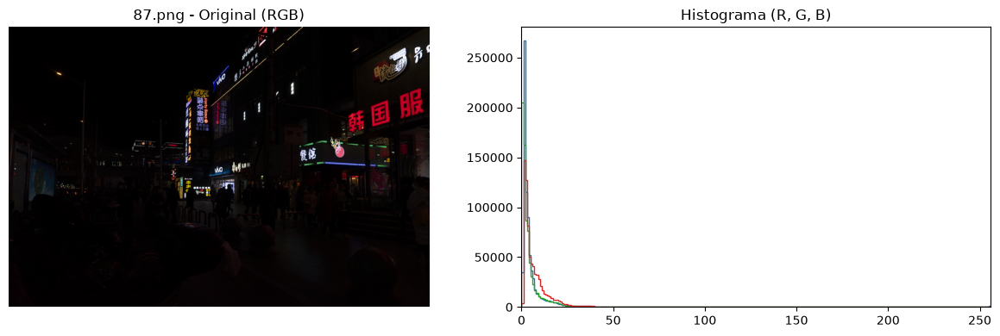

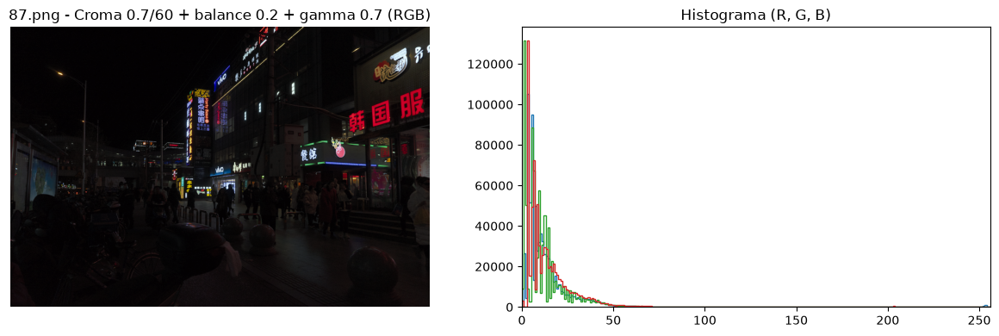

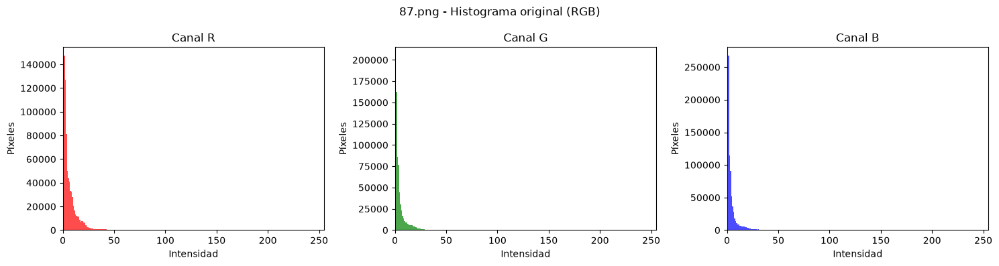

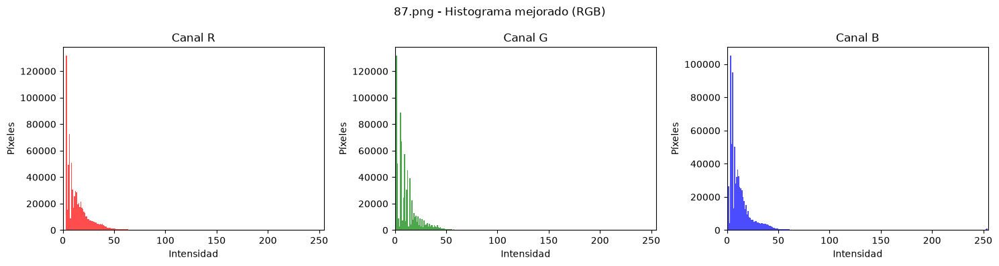

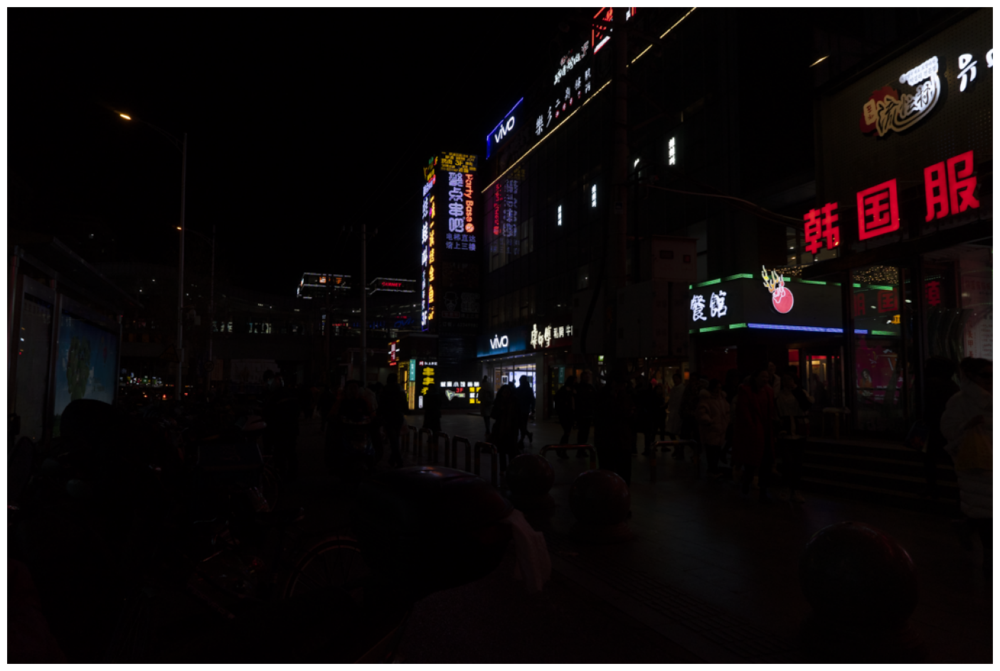

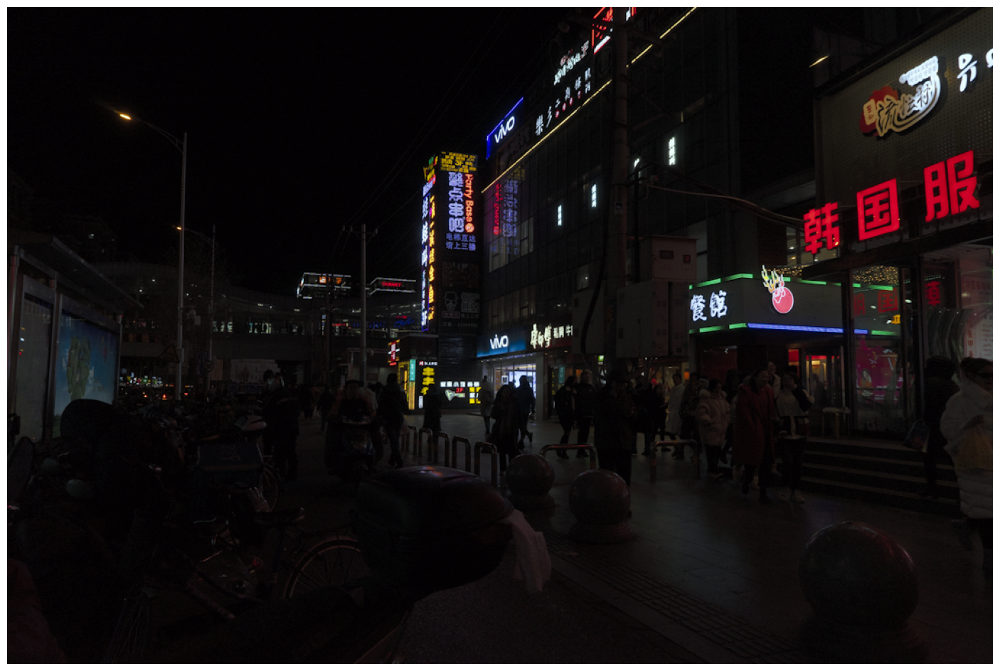

In [5]:
img_rgb = load_rgb("87.png")
print("Antes:  media=%.1f p50=%.1f" % (img_rgb.mean(), np.median(img_rgb)))
print("        medias R/G/B =", img_rgb.reshape(-1, 3).mean(axis=0).round(1))

img_clean = clean_shadow_chroma(img_rgb, amount=0.7, threshold=60)
img_wb = white_balance_gray_world(img_clean, strength=0.2)
result_87 = gamma_luminance_rgb(img_wb, gamma=0.7)

clip_orig = (img_rgb.max(axis=2) >= 255).mean() * 100
clip_res = (result_87.max(axis=2) >= 255).mean() * 100
print("Despues: media=%.1f p50=%.1f" % (result_87.mean(), np.median(result_87)))
print("         medias R/G/B =", result_87.reshape(-1, 3).mean(axis=0).round(1))
print("         pixeles recortados: original %.2f%% -> mejorada %.2f%%" % (clip_orig, clip_res))

plot_img_and_hist(img_rgb, "87.png - Original (RGB)")
plot_img_and_hist(result_87, "87.png - Croma 0.7/60 + balance 0.2 + gamma 0.7 (RGB)")
plot_hist_rgb(img_rgb, "87.png - Histograma original (RGB)")
plot_hist_rgb(result_87, "87.png - Histograma mejorado (RGB)")

fig, ax = plt.subplots(figsize=(18, 12))  # ancho, alto en pulgadas
ax.imshow(img_rgb)
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(18, 12))  # ancho, alto en pulgadas
ax.imshow(result_87)
ax.axis("off")
plt.show()


## Pipeline 3 — `156.png`: lineal en sombras 3.1 (final) + curva a trozos (comparación)

**Naturaleza (RGB):** media 16.2 y `p99 = 195`: tiene sombras muy oscuras y una **zona muy brillante** (escaparate con luces y percheros) que hay que conservar.

**Problema:** levantar o comprimir también medios/altos deforma el escaparate y los percheros. Lo que se quiere es **subir solo las sombras** y dejar el resto igual que el original.

**Pipeline 3.1 (solución final): corrección lineal enmascarada a sombras.**
- `linear_rgb` con `α = (2.9, 3.4, 3.4)` y `β = 0` sube el contraste sin levantar el negro (el α de R es algo menor porque las sombras ya vienen con dominante roja).
- La **máscara de sombras** (`shadow_mask`, brillo < 80) aplica esa corrección solo donde el brillo es menor que 80; el escaparate y las luces (brillo > 80) quedan intactos.
- **Resultado:** media 16.2 → 26.9, `p99` se mantiene en 195, recorte ~0.16 %.

**Pipeline 3 (comparación): función a trozos (`np.interp`)** con `[0, 20, 60, 100, 255] → [0, 40, 90, 100, 255]`: sube las sombras y, a partir de 100, deja la identidad. Da media 23.3, pero la curva sigue tocando los pliegues oscuros de la sudadera (< 100) y reduce su contraste local; por eso se conserva solo como comparación.

La curva a trozos se aplica por igual a R, G y B; la corrección lineal 3.1 usa un α ligeramente menor en R porque las sombras ya vienen con dominante roja.


Antes:  media=16.2 p99=195.0
A trozos:    media=23.3 p99=195.0
Pipeline3.1: media=26.9 p99=195.0


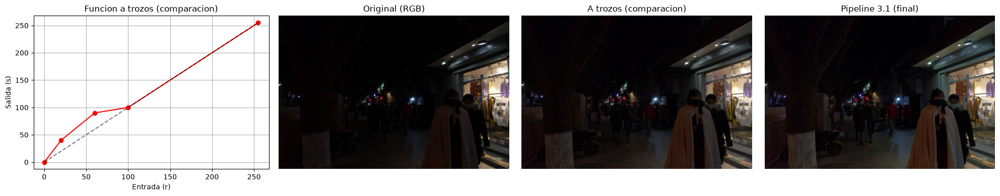

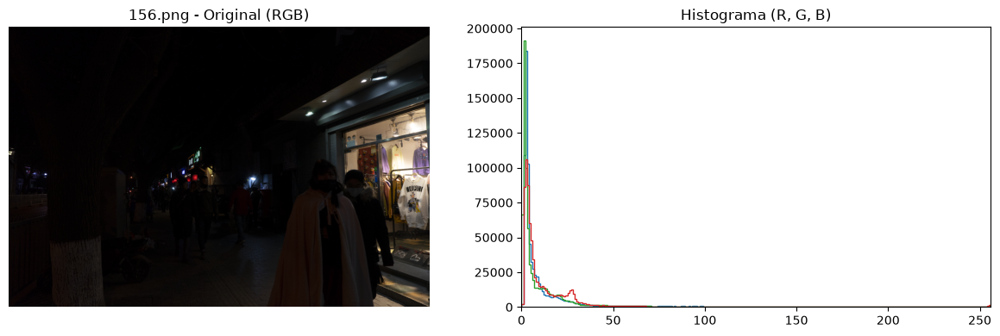

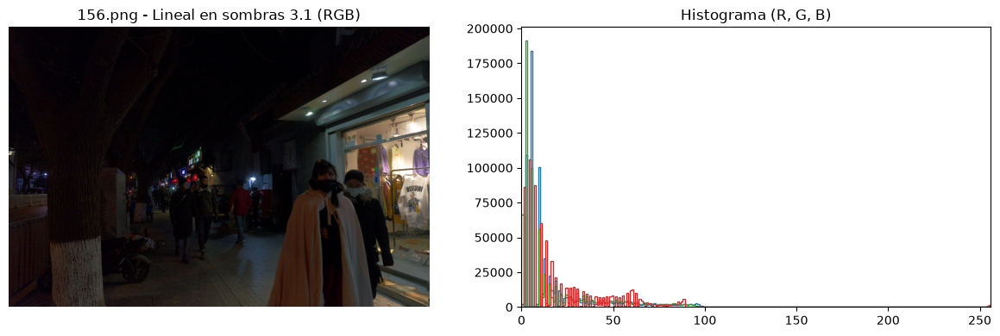

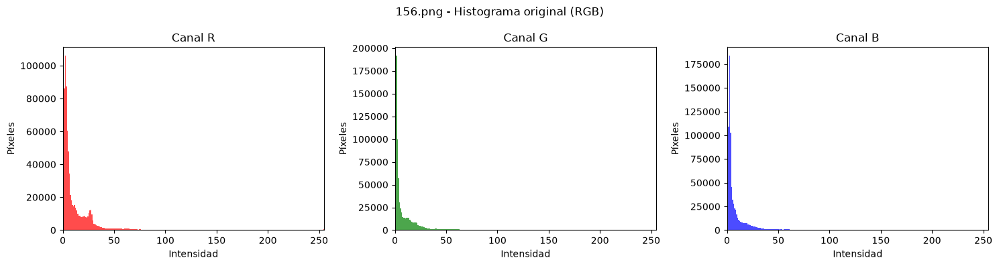

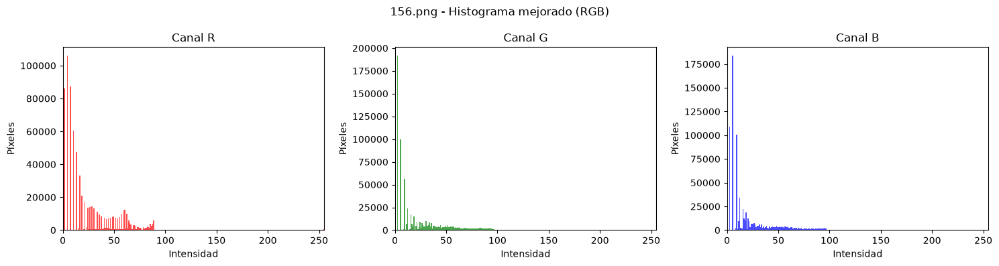

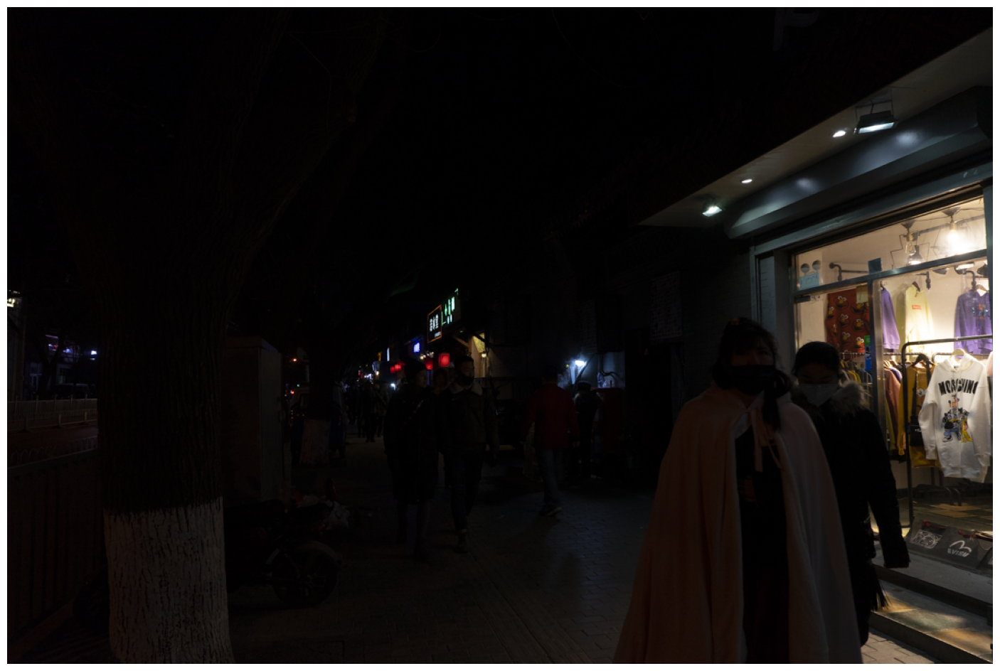

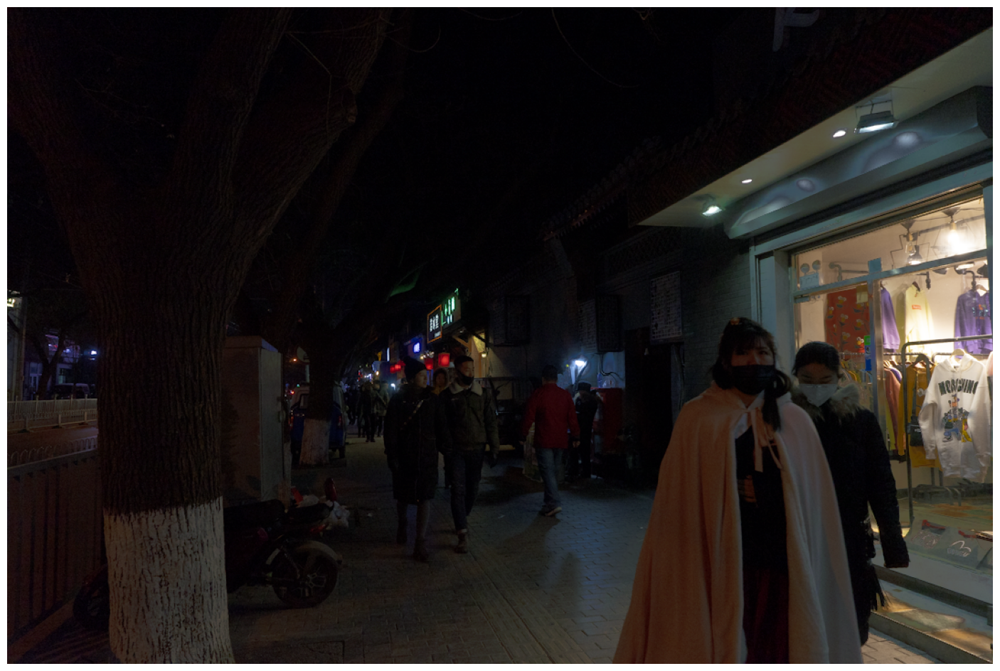

In [6]:
img_orig = load_rgb("156.png")
print("Antes:  media=%.1f p99=%.1f" % (img_orig.mean(), np.percentile(img_orig, 99)))

# Comparación: función a trozos (a partir de 100 la curva es la identidad).
x_points = [0, 20, 60, 100, 255]
y_points = [0, 40, 90, 100, 255]
result_156_piecewise = np.interp(img_orig.ravel(), x_points, y_points).reshape(img_orig.shape).astype(np.uint8)

# Solución final (Pipeline 3.1): corrección lineal aplicada solo en sombras (brillo < 80).
result_156 = linear_shadow_rgb(img_orig)

print("A trozos:    media=%.1f p99=%.1f" % (result_156_piecewise.mean(), np.percentile(result_156_piecewise, 99)))
print("Pipeline3.1: media=%.1f p99=%.1f" % (result_156.mean(), np.percentile(result_156, 99)))

plt.figure(figsize=(20, 4))
plt.subplot(1, 4, 1)
plt.plot(x_points, y_points, marker='o', color='red')
plt.plot([0, 255], [0, 255], 'k--', alpha=0.5)
plt.title("Funcion a trozos (comparacion)")
plt.xlabel("Entrada (r)")
plt.ylabel("Salida (s)")
plt.grid(True)
plt.subplot(1, 4, 2)
plt.imshow(img_orig); plt.title("Original (RGB)"); plt.axis('off')
plt.subplot(1, 4, 3)
plt.imshow(result_156_piecewise); plt.title("A trozos (comparacion)"); plt.axis('off')
plt.subplot(1, 4, 4)
plt.imshow(result_156); plt.title("Pipeline 3.1 (final)"); plt.axis('off')
plt.tight_layout(); plt.show()

plot_img_and_hist(img_orig, "156.png - Original (RGB)")
plot_img_and_hist(result_156, "156.png - Lineal en sombras 3.1 (RGB)")
plot_hist_rgb(img_orig, "156.png - Histograma original (RGB)")
plot_hist_rgb(result_156, "156.png - Histograma mejorado (RGB)")

fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(img_orig)
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(result_156)
ax.axis("off")
plt.show()


## Pipeline 4 — `521.png`: ecualización global limitada (RGB)

**Naturaleza (RGB):** la más extrema: media 5.3, mediana 2, `p99 = 105`. Casi todo está a negro y hay un sujeto pequeño. El 66 % de los píxeles está en 0–1 y solo el ~2 % supera 40: el histograma tiene un pico enorme pegado a cero (el cielo, que además es en gran parte ruido).

**Método del laboratorio:** **ecualización de histograma global**, aplicada **canal a canal** sobre R, G y B, pero **limitando el pico del histograma** (`clip_frac`). La ecualización pura amplifica ese pico casi negro y saca mucho ruido; al recortarlo antes de calcular la CDF se reparte el poco detalle real sin amplificar el suelo de ruido. Es un **LUT global**: punto a punto, no emborrona y conserva la estructura.

**Detalle:** `clip_frac=0.02` limita cada bin del histograma de cada canal al 2 % del total de píxeles y reparte el exceso, de modo que el pico gigante en 0 no domina la CDF; el resultado se **mezcla al 50 %** con el original para un aspecto más natural.

**Resultado:** media 5.3 → 13.6, mediana 2 → 8. Frente a la versión anterior (gamma + ecualización) baja el ruido en zonas planas (15.6 → 4.8) y la dominante de color (7.8 → 1.8), manteniendo la estructura (correlación de gradientes 0.97).

**Por qué no gamma:** ya se usa en el Pipeline 2 (`87`), y repetiría método. **Por qué no CLAHE:** es local y ya se usa en `81`; en `521` el problema es el histograma global pegado a cero.


In [7]:
def equalize_clipped_rgb(image, clip_frac=0.02, blend=1.0):
    # Ecualización global por canal limitando el pico del histograma:
    # evita amplificar el ruido de una zona casi negra.
    out = []
    for c in range(3):
        h = np.bincount(image[..., c].ravel(), minlength=256).astype(np.float64)
        cap = clip_frac * h.sum()
        extra = np.maximum(h - cap, 0).sum()
        h = np.minimum(h, cap) + extra / 256.0
        cdf = h.cumsum()
        lut = np.clip(np.round(cdf / cdf[-1] * 255), 0, 255).astype(np.uint8)
        out.append(cv2.LUT(image[..., c], lut))
    eq = np.stack(out, axis=-1)
    if blend < 1.0:
        return cv2.addWeighted(image, 1.0 - blend, eq, blend, 0)
    return eq


Antes:  media=5.3 p50=2.0
Despues: media=20.6 p50=12.0


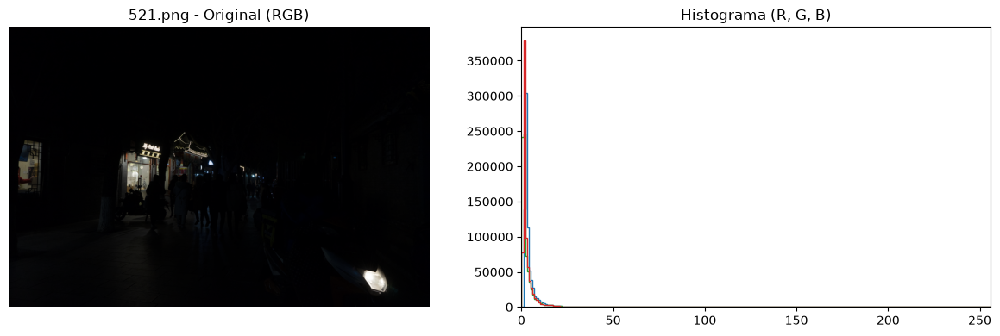

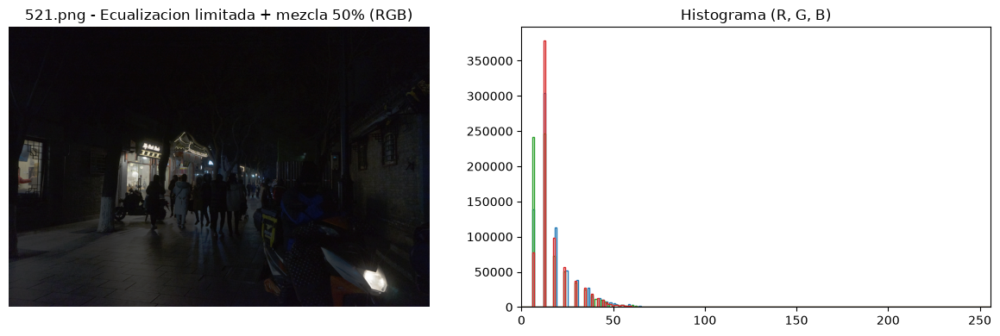

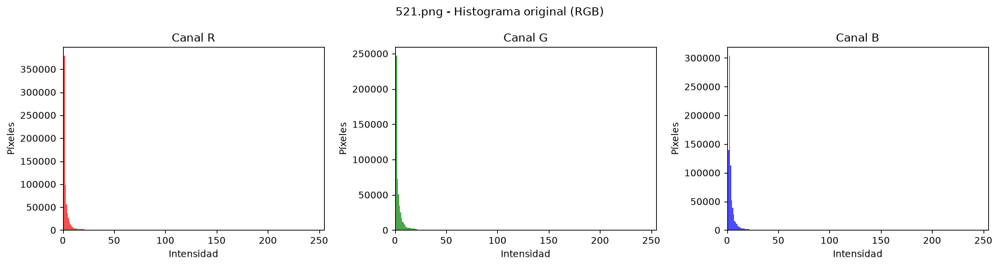

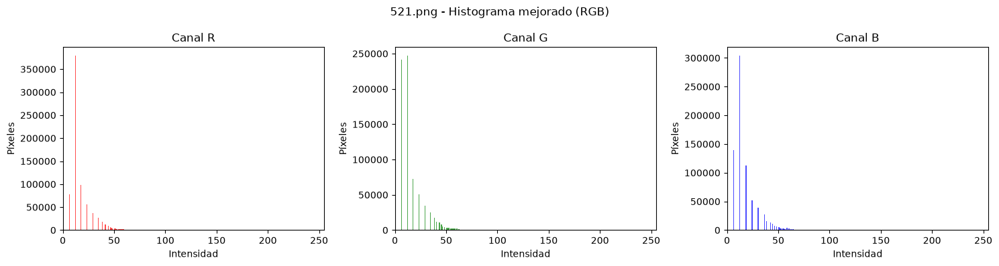

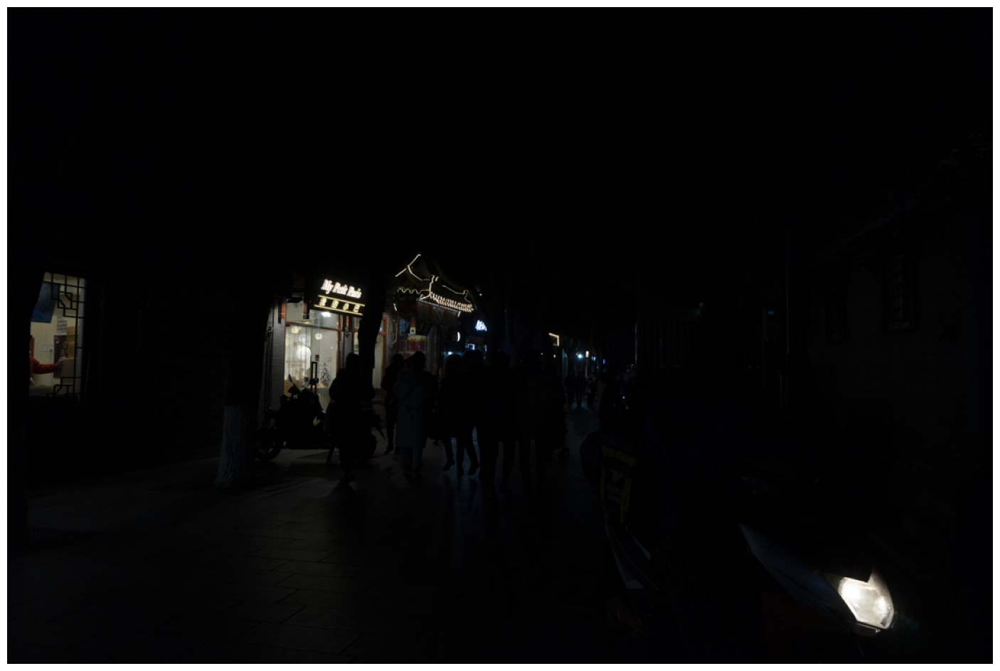

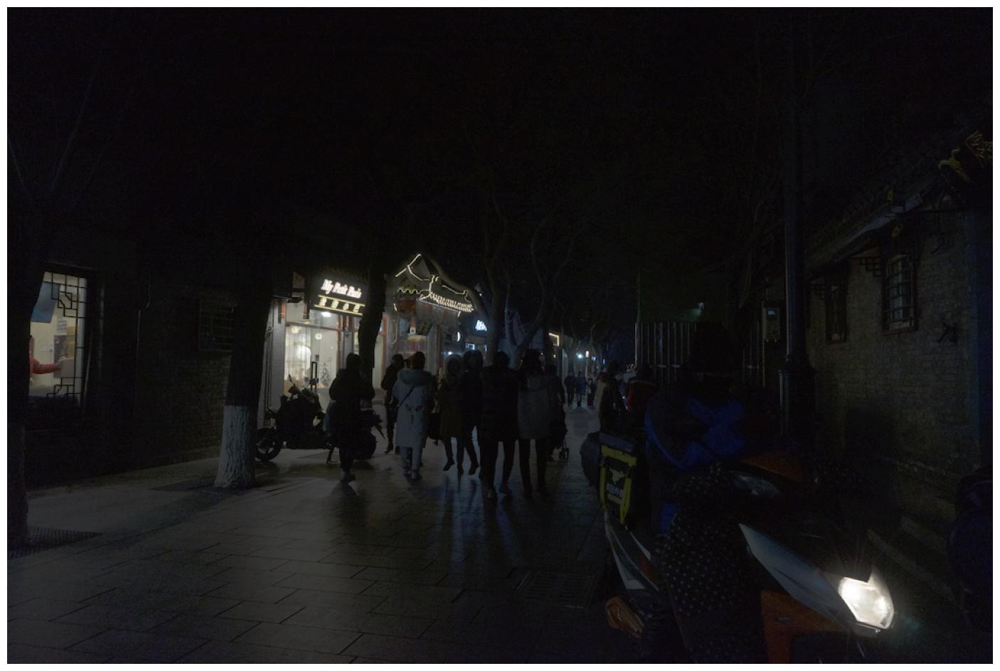

In [25]:
img_rgb = load_rgb("521.png")
print("Antes:  media=%.1f p50=%.1f" % (img_rgb.mean(), np.median(img_rgb)))

result_521 = equalize_clipped_rgb(img_rgb, clip_frac=0.04, blend=0.5)

print("Despues: media=%.1f p50=%.1f" % (result_521.mean(), np.median(result_521)))
plot_img_and_hist(img_rgb, "521.png - Original (RGB)")
plot_img_and_hist(result_521, "521.png - Ecualizacion limitada + mezcla 50% (RGB)")

plot_hist_rgb(img_rgb, "521.png - Histograma original (RGB)")
plot_hist_rgb(result_521, "521.png - Histograma mejorado (RGB)")

fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(img_rgb)
ax.axis("off")
plt.show()

fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(result_521)
ax.axis("off")
plt.show()


## Galería final (RGB): original vs. mejorada


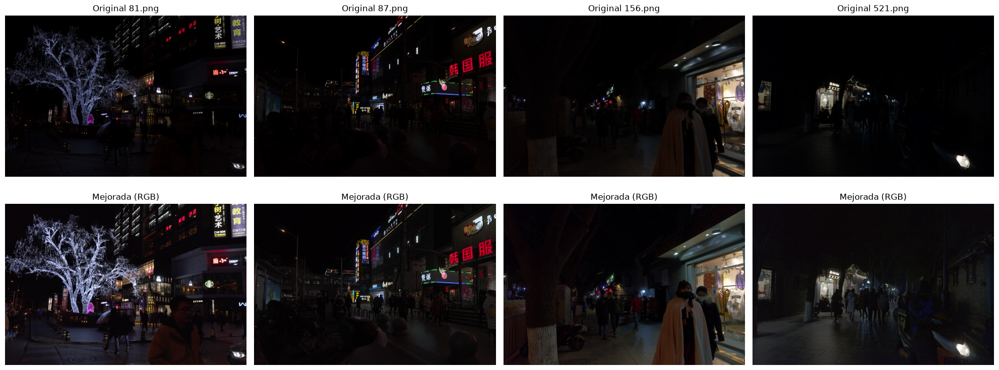

In [26]:
pairs = [
    ("81.png", result_81),
    ("87.png", result_87),
    ("156.png", result_156),
    ("521.png", result_521),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, (name, res) in enumerate(pairs):
    axes[0, j].imshow(load_rgb(name))
    axes[0, j].set_title("Original " + name)
    axes[0, j].axis('off')
    axes[1, j].imshow(res)
    axes[1, j].set_title("Mejorada (RGB)")
    axes[1, j].axis('off')
plt.tight_layout()
plt.show()


## Conclusiones

- No hay un pipeline universal: **cada histograma pide una técnica distinta**.
- Todos los pipelines trabajan **en RGB**: las curvas de punto y el LUT de ecualización se aplican por igual a R, G y B; CLAHE y ecualización se aplican canal a canal y se vuelven a unir, sin pasar por grises ni HSV.
- `81` (oscura con estructura) → **corrección lineal (α=2, β=2) + CLAHE clip 2/8×8 + mezcla 10 %**: brillo/contraste global y detalle local sin amplificar en exceso el ruido.
- `87` (muy oscura, dominante roja, carteles luminosos) → **limpieza de croma + balance suave + gamma 0.7**: aclara sin amplificar el rojo ni recortar las luces.
- `156` (sombras + escaparate brillante) → **corrección lineal enmascarada a sombras (Pipeline 3.1)** con `β=0` para no levantar el negro y con el escaparate protegido por la máscara de brillo (< 80); la función a trozos queda como comparación.
- `521` (casi negra, pico de ruido en 0) → **ecualización global con recorte de histograma**: limita el pico antes de la CDF, así reparte el poco detalle real sin amplificar el ruido del cielo.
- Recordatorio del laboratorio: **min-max no sirve cuando ya hay 0 y 255**.


## Evaluación de calidad de los pipelines

Métricas **sin referencia**: las imágenes originales son las *degradadas*, no una referencia de calidad (comparar contra ellas con PSNR/SSIM premiaría no hacer nada). La original se usa solo como referencia de **estructura** (correlación de gradientes). `ruido` se mide en zonas planas y `detalle` en bordes, ambas definidas sobre la original, para no confundir grano con textura.

`%_subexp` y `%_recort` se miden sobre la luminancia `Y` (`Y<5` y `Y>=250`); `%_clip255` cuenta píxeles con algún canal saturado a 255 (es el que coincide con los recortes por canal que imprimen las celdas de cada pipeline). La fila `P3 a trozos` es solo comparación; la solución final de `156` es `P3.1`. `detalle` mide el gradiente medio en bordes (nitidez/textura) y `ruido` la desviación del Laplaciano en zonas planas; conviene leerlos juntos porque un filtro agresivo baja ambos.


imagen   version        Y_medio   %_subexp   %_recort  %_clip255  contraste   entropia    detalle      ruido      color  dominante estructura
---------------------------------------------------------------------------------------------------------------------------------------------
81.png   original         12.86      57.66       0.03       0.05      26.62       4.59     352.97       2.35      15.17       3.29       1.00
81.png   mejorada         34.07       6.58       0.14       0.06      48.41       6.03     567.17       7.10      23.06       6.40       0.59

87.png   original          8.19      68.82       0.07       0.19      22.89       3.95     275.38       1.91      21.67       4.37       1.00
87.png   mejorada         15.84      26.76       0.00       0.03      25.02       5.03     279.17       5.49      23.51       4.29       0.98

156.png  original         16.31      55.49       0.22       0.16      34.51       4.83     181.36       2.53      13.21       4.73       1.00
156.

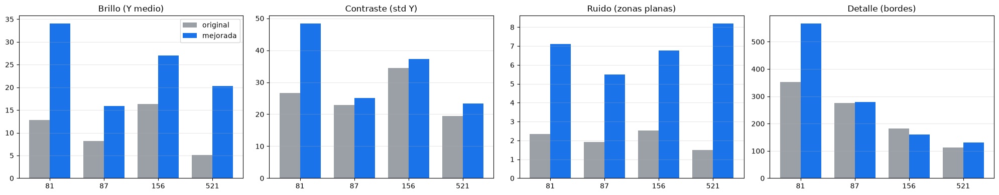

In [27]:
# ============================================================
# Evaluación de la calidad de todos los pipelines
# ============================================================
# No existe una imagen "buena" de referencia: las originales son
# las imágenes DEGRADADAS (oscuras/ruidosas). Por eso usamos
# métricas SIN REFERENCIA (brillo, contraste, ruido, color) y la
# original solo como referencia de ESTRUCTURA (correlación de
# gradientes: comprueba que no se inventa ni se borra contenido).

def to_luma(img):
    return (0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]).astype(np.float32)

def grad_mag(y):
    gx = cv2.Sobel(y, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(y, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.magnitude(gx, gy)

def entropy_y(y):
    hist = np.bincount(np.clip(y, 0, 255).astype(np.uint8).ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def colorfulness(img):
    r, g, b = [img[..., i].astype(np.float32) for i in range(3)]
    rg = r - g
    yb = 0.5 * (r + g) - b
    return float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))

def image_metrics(original, enhanced):
    # Las zonas (planas / borde) se fijan sobre la original para medir
    # "ruido" y "detalle" SIEMPRE en los mismos píxeles.
    y = to_luma(enhanced)
    y_orig = to_luma(original)
    g_orig = grad_mag(y_orig)
    flat = g_orig <= np.percentile(g_orig, 40)   # cielo / fondo liso
    edge = g_orig >= np.percentile(g_orig, 95)   # sujeto / textura / bordes
    grad = grad_mag(y)
    lap = cv2.Laplacian(y, cv2.CV_32F)
    corr = np.corrcoef(g_orig[edge], grad[edge])[0, 1] if edge.sum() > 10 else np.nan
    means = enhanced.reshape(-1, 3).mean(axis=0)
    return {
        "Y_medio":   y.mean(),                  # brillo (0-255)
        "%_subexp":  (y < 5).mean() * 100,      # % casi negro
        "%_recort":  (y >= 250).mean() * 100,   # % luces quemadas en luminancia
        "%_clip255": (enhanced.max(axis=2) >= 255).mean() * 100,  # % algún canal saturado
        "contraste": y.std(),                   # contraste RMS
        "entropia":  entropy_y(y),              # niveles usados (bits)
        "detalle":   grad[edge].mean(),         # nitidez en bordes
        "ruido":     lap[flat].std(),           # grano en zonas planas
        "color":     colorfulness(enhanced),    # Hasler-Süsstrunk
        "dominante": means.max() - means.min(), # desequilibrio R/G/B
        "estructura": corr,                     # fidelidad de bordes vs original
    }

# Pipelines guardados en las celdas anteriores
specs = [
    ("81.png",  "P1 lineal+CLAHE",        "result_81"),
    ("87.png",  "P2 croma+balance+gamma", "result_87"),
    ("156.png", "P3.1 lineal sombras",    "result_156"),
    ("521.png", "P4 ecualizacion limitada", "result_521"),
]
main_rows = []
for name, label, var in specs:
    if var in globals():
        main_rows.append((name, label, globals()[var]))
    else:
        print(f"Falta {var}: ejecuta antes la celda de ese pipeline.")

# Función a trozos de 156: solo comparación (la final es P3.1 = result_156)
extra_rows = []
if "result_156_piecewise" in globals():
    extra_rows.append(("156.png", "P3 a trozos", result_156_piecewise))

all_rows = main_rows + extra_rows

cols = ["Y_medio", "%_subexp", "%_recort", "%_clip255", "contraste", "entropia",
        "detalle", "ruido", "color", "dominante", "estructura"]
header = f"{'imagen':<9}{'version':<11}" + "".join(f"{c:>11}" for c in cols)
print(header)
print("-" * len(header))
for name, label, enh in all_rows:
    orig = load_rgb(name)
    for tag, img in [("original", orig), ("mejorada", enh)]:
        m = image_metrics(orig, img)
        print(f"{name:<9}{tag:<11}" + "".join(f"{m[c]:>11.2f}" for c in cols))
    print()

# --- Gráfico comparativo original vs mejorada ---
if main_rows:
    names = [r[0].replace(".png", "") for r in main_rows]
    plots = [("Y_medio", "Brillo (Y medio)"), ("contraste", "Contraste (std Y)"),
             ("ruido", "Ruido (zonas planas)"), ("detalle", "Detalle (bordes)")]
    x = np.arange(len(main_rows))
    w = 0.38
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, (key, title) in zip(axes, plots):
        ov = [image_metrics(load_rgb(r[0]), load_rgb(r[0]))[key] for r in main_rows]
        ev = [image_metrics(load_rgb(r[0]), r[2])[key] for r in main_rows]
        ax.bar(x - w / 2, ov, w, label="original", color="#9aa0a6")
        ax.bar(x + w / 2, ev, w, label="mejorada", color="#1a73e8")
        ax.set_xticks(x)
        ax.set_xticklabels(names)
        ax.set_title(title)
        ax.grid(axis="y", alpha=0.3)
    axes[0].legend()
    plt.tight_layout()
    plt.show()
